In [1]:
import sys

sys.argv = [""]  # to avoid issues with Jupyter and argparse

In [2]:
import numpyro

numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import arviz as az
import xarray
from scipy.stats import qmc
from ipywidgets import interact, IntSlider
import matplotlib.pyplot as plt
from pathlib import Path
import json
import ICIW_Plots

plt.style.use("ICIWstyle")

In [3]:
from HSA_Cam_D_005 import (
    calculate_partial_pressures,
    predict_Mo1,
    predict_Mo4,
    JSD_marginal,
    JSD_between_predictions,
    calculate_disagreement,
    LHSDOE,
    generate_synthetic_data,
    run_inference_Mo1,
    run_inference_Mo4,
    find_opt_candidate,
)
from HSA_Mo_D_004_numpyro import validate_against_holdout

In [4]:
# exp_run_name = "scornful-placebo"  # VI small test
exp_run_name = "injured-lift"  # full run with optimized settings
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
Mo1_trace_files = sorted(data_path.glob("Mo1_trace_*.nc"))
Mo4_trace_files = sorted(data_path.glob("Mo4_trace_*.nc"))

In [5]:
idatas = {
    "Mo1": [],
    "Mo4": [],
}

for Mo1_trace_file, Mo4_trace_file in zip(Mo1_trace_files, Mo4_trace_files):
    Mo1_idata = az.from_netcdf(Mo1_trace_file)
    Mo4_idata = az.from_netcdf(Mo4_trace_file)
    idatas["Mo1"].append(Mo1_idata)
    idatas["Mo4"].append(Mo4_idata)

In [6]:
for model_idatas in idatas.values():
    for i, idata in enumerate(model_idatas):
        if i == 0:
            continue
        else:
            idata.add_groups({"prior": model_idatas[i - 1].posterior})

In [7]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [8]:
proposals = jnp.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = jnp.array(exp_summary["trials"][-1]["observed"]["y"])

In [9]:
display(proposals)
display(proposals.shape)

Array([[4.8858200e+02, 8.6007404e+00, 2.7542720e+00, 4.1615823e+02,
        4.7536072e+02, 5.5344540e-01],
       [5.4535034e+02, 4.5957446e+00, 1.7749146e+00, 8.9885181e+02,
        5.1642303e+02, 8.5581857e-01],
       [5.8481836e+02, 5.6127381e+00, 4.3500042e-01, 5.9828156e+02,
        8.1154871e+02, 7.0938879e-01],
       [5.1035834e+02, 7.6888857e+00, 2.1929657e+00, 2.2906201e+02,
        2.8034088e+02, 9.9091552e-02],
       [4.6956689e+02, 4.2984872e+00, 3.3243811e+00, 8.6442273e+02,
        9.5516235e+02, 2.2009242e-01],
       [5.2787878e+02, 6.1236448e+00, 3.9265208e+00, 9.0297340e+01,
        7.2464355e+01, 4.5812908e-01],
       [5.7363574e+02, 6.9056616e+00, 1.2237009e+00, 6.8625873e+02,
        2.0807574e+02, 8.9750528e-01],
       [4.5858295e+02, 3.6537936e+00, 7.2978091e-01, 3.0453455e+02,
        7.2061310e+02, 3.3192843e-01],
       [6.0000000e+02, 9.0000000e+00, 2.0000000e-01, 1.0000000e+03,
        1.0000000e+03, 1.0000000e+00],
       [6.0000000e+02, 3.0000000e+00,

(12, 6)

In [10]:
r_obs.shape

(10, 12, 1, 1)

In [11]:
@interact(
    i=IntSlider(
        min=0,
        max=4,
        step=1,
        value=0,
        description="Experiment Index",
    ),
    j=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    ),
)
def interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$t$ / h",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
        # yscale="log",
        # ylim=(1e-6, 1e-5),
        # xlim=(450, 600),
    )

    T_prop = proposals[j : j + 1, 0:1]
    p_prop = proposals[j : j + 1, 1:2]
    c2h_prop = proposals[j : j + 1, 2:3]
    c2m_prop = proposals[j : j + 1, 3:4]
    c2w_prop = proposals[j : j + 1, 4:5]
    c2i_prop = proposals[j : j + 1, 5:6]

    pi_prop = calculate_partial_pressures(
        p_total=p_prop,
        c2h_ratio=c2h_prop,
        c2m_ratio=c2m_prop,
        c2w_ratio=c2w_prop,
        c2i_ratio=c2i_prop,
    )

    r_pred1 = predict_Mo1(
        idatas["Mo1"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )
    r_pred4 = predict_Mo4(
        idatas["Mo4"][i],
        T_prop,
        pi_prop,
        key="posterior",
    )

    display(proposals[j])
    display(r_pred1.shape)

    ax.plot(r_obs[:, j, 0, 0], "ro", label="Observed data")
    ax.plot(r_pred1.mean(axis=3)[:, 0, 0], label="Predicted data Mo1")
    ax.fill_between(
        jnp.arange(r_pred1.shape[0]),
        jnp.quantile(r_pred1[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred1[:, 0, 0, :], 0.95, axis=1),
        color="C0",
        alpha=0.2,
        label="90% credible interval",
    )
    ax.plot(r_pred4.mean(axis=3)[:, 0, 0], label="Predicted data Mo4")
    ax.fill_between(
        jnp.arange(r_pred4.shape[0]),
        jnp.quantile(r_pred4[:, 0, 0, :], 0.05, axis=1),
        jnp.quantile(r_pred4[:, 0, 0, :], 0.95, axis=1),
        color="C1",
        alpha=0.2,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Experiment Index', max=4), IntSlider(value=0, descriptio…

Array([6.0000000e+02, 9.0000000e+00, 2.0000000e-01, 2.7052737e+02,
       3.0151831e+02, 1.0000000e+00], dtype=float32)

(10, 1, 1, 25)

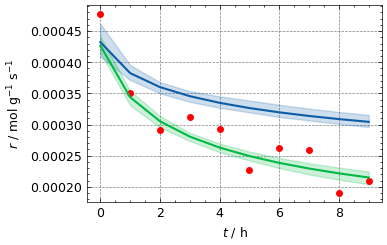

In [12]:
interactive(4, 11)

/tmp/ipykernel_103799/1707754344.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



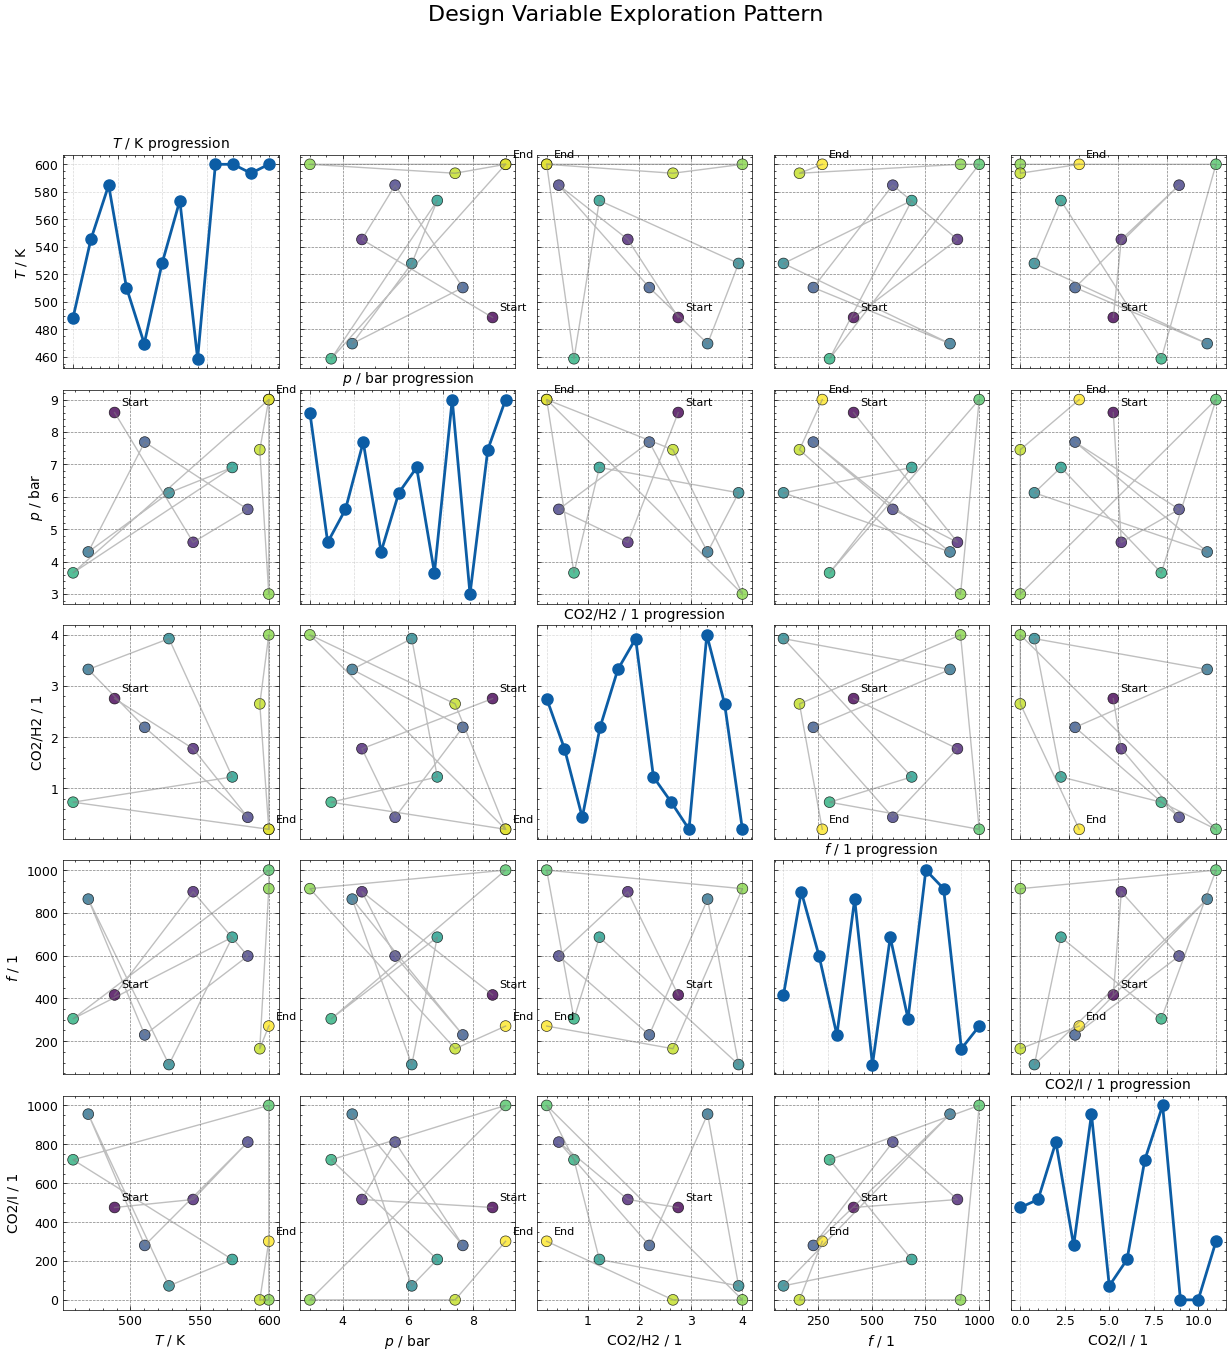

In [13]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = jnp.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## claculate the RMSE

In [14]:
test_data = xarray.open_dataset(Path("data/test_HSA_Da_D_004.nc"))
display(test_data)

<xarray.Dataset> Size: 160kB
Dimensions:    (sample: 1000, parameter: 6, species: 5, time: 10, component: 1,
                draws: 1)
Coordinates:
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
  * time       (time) int64 80B 0 1 2 3 4 5 6 7 8 9
  * component  (component) <U1 4B 'a'
  * draws      (draws) int64 8B 0
Data variables:
    samples    (sample, parameter) float64 48kB ...
    T          (sample) float32 4kB ...
    p          (sample, species) float32 20kB ...
    latent_r   (time, sample, component, draws) float32 40kB ...
    obs_r      (time, sample, component, draws) float32 40kB ...
Attributes:
    noise:    homoscedastic
    sigma:    1e-05

In [15]:
postdatas = {
    "Mo1": [],
    "Mo4": [],
}
for model_name, model_idatas in idatas.items():
    for i, idata in enumerate(model_idatas):
        postdata = validate_against_holdout(idata, test_data, num_samples=985)
        postdatas[model_name].append(postdata)

(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


...

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



(1000, 1) (1000, 5) None


/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



In [16]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[
        var_name
    ].values  # shape (chain=1, draw=1, obs, times=10, 1)
    pred = postdata.posterior_predictive[
        var_name
    ].values  # shape (chain=1, draw, obs, times=10, n_samples)
    res = true - pred
    rmse_vals = jnp.sqrt(jnp.mean(res**2, axis=(2, 3, 4))).squeeze()
    rmse_da = xarray.DataArray(
        data=rmse_vals,
        dims=["draw"],
    )
    return rmse_da

In [17]:
RMSEs = {
    "Mo1": [],
    "Mo4": [],
}
for model_name, postdatas_list in postdatas.items():
    for postdata in postdatas_list:
        RMSEs[model_name].append(bRMSE(postdata, "r_lat"))
    RMSEs[model_name] = jnp.array(RMSEs[model_name])

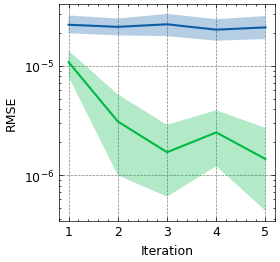

In [18]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="Iteration",
    ylabel="RMSE",
    yscale="log",
)
ax.plot(jnp.arange(1, len(RMSEs["Mo1"]) + 1), RMSEs["Mo1"].mean(axis=1))
ax.fill_between(
    jnp.arange(1, len(RMSEs["Mo1"]) + 1),
    jnp.quantile(RMSEs["Mo1"], 0.025, axis=1),
    jnp.quantile(RMSEs["Mo1"], 0.975, axis=1),
    alpha=0.3,
)
ax.plot(jnp.arange(1, len(RMSEs["Mo4"]) + 1), RMSEs["Mo4"].mean(axis=1))
ax.fill_between(
    jnp.arange(1, len(RMSEs["Mo4"]) + 1),
    jnp.quantile(RMSEs["Mo4"], 0.025, axis=1),
    jnp.quantile(RMSEs["Mo4"], 0.975, axis=1),
    alpha=0.3,
)